# Практическая работа 3 "Pillow Library (PIL)"

1. Задание: Необходимо повторить весь код из примера с одним своим изображением, что означает, что все манипуляции должны быть произведены с одним изображением.

2. Прикрепить файл в формате .ipynb. 

3. Балл за задание: 3.

## Немного вводной части

<p>Задачи обработки изображений и компьютерного зрения включают отображение, обрезку, переворачивание, поворот, сегментацию изображения, классификацию, восстановление изображения, распознавание изображений, создание изображений. Кроме того, иногда работа с изображениями требует хранения, передачи и сбора изображений через Интернет. 
<p>Python - отличный выбор, поскольку в нем есть множество инструментов для обработки изображений, компьютерного зрения и библиотек искусственного интеллекта. Также, в нем есть множество библиотек для работы с файлами в облачных сервисах и в сети Интернете. Цифровое изображение - это просто файл на вашем компьютере. В данной практической работе вы получите представление об этих файлах и научитесь работать с ними с помощью библиотеки Pillow (PIL).

### Загрузка изображений для практической работы:

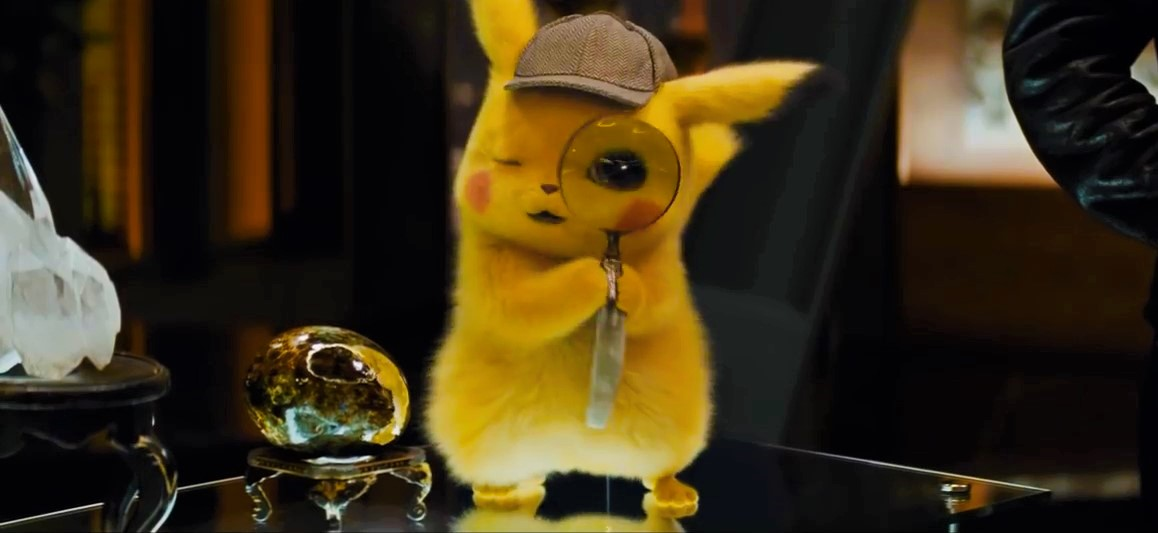

In [1]:
from IPython.display import Image
Image("pika.jpg")

Для начала, необходимо определить вспомогательную функцию для объединения двух изображений:

In [2]:
def get_concat_h(im1, im2):
    #https://note.nkmk.me/en/python-pillow-concat-images/
    dst = Image.new('RGB', (im1.width + im2.width, im1.height))
    dst.paste(im1, (0, 0))
    dst.paste(im2, (im1.width, 0))
    return dst

### Изображения и пути хранения

Изображение хранится в виде файла на вашем компьютере. Ниже мы определяем my_image как имя файла в этом каталоге.

In [3]:
my_image = "pika.jpg"

<p>Имя файла состоит из двух частей: имени файла и расширения, разделенных точкой (`.`). Расширение определяет формат изображения. Существует два популярных формата изображений: изображение Joint Photographic Expert Group (или .jpg, .jpeg) и Portable Network Graphics (или .png). Эти типы файлов упрощают работу с изображениями. Например, они могут сжимать изображение, что позволяет занимать меньше места для хранения изображения.
<p>Файлы изображений хранятся в файловой системе вашего компьютера. Его местоположение указывается с помощью уникального «пути». Вы можете найти путь к вашему текущему рабочему каталогу с помощью модуля Python `os`. Модуль `os` предоставляет функции для взаимодействия с файловой системой, например, создание или удаление каталога (папки), перечисление ее содержимого, изменение и идентификация текущего рабочего каталога.

In [4]:
import os
cwd = os.getcwd()
cwd

'C:\\Users\\ppblondy\\Dropbox\\Универ лекции\\2022-2023\\1 семестр\\Поиск и обработка\\Практическая_работа_№_1_Базовые манипуляции в библиотеке Pillow'

Путь к изображению можно найти с помощью следующей строки кода

In [5]:
image_path = os.path.join(cwd, my_image)
image_path

'C:\\Users\\ppblondy\\Dropbox\\Универ лекции\\2022-2023\\1 семестр\\Поиск и обработка\\Практическая_работа_№_1_Базовые манипуляции в библиотеке Pillow\\pika.jpg'

### Загрузка изображений

Библиотека Pillow (PIL) - популярная библиотека для загрузки изображений в Python. Кроме того, многие другие библиотеки, такие как «Keras» и «PyTorch», используют эту библиотеку для работы с
изображениями. Модуль `Image` предоставляет функции для загрузки изображений и сохранения изображений в файловой системе. Импортируем его из `PIL`.

In [7]:
from PIL import Image

Если изображение находится в текущем рабочем каталоге, вы можете загрузить изображение следующим образом, используя имя файла изображения и создать объект PIL Image:

In [10]:
image = Image.open(my_image)
type(image)

PIL.JpegImagePlugin.JpegImageFile

Если вы работаете в среде Jupyter, вы можете просмотреть изображение, вызвав саму переменную:

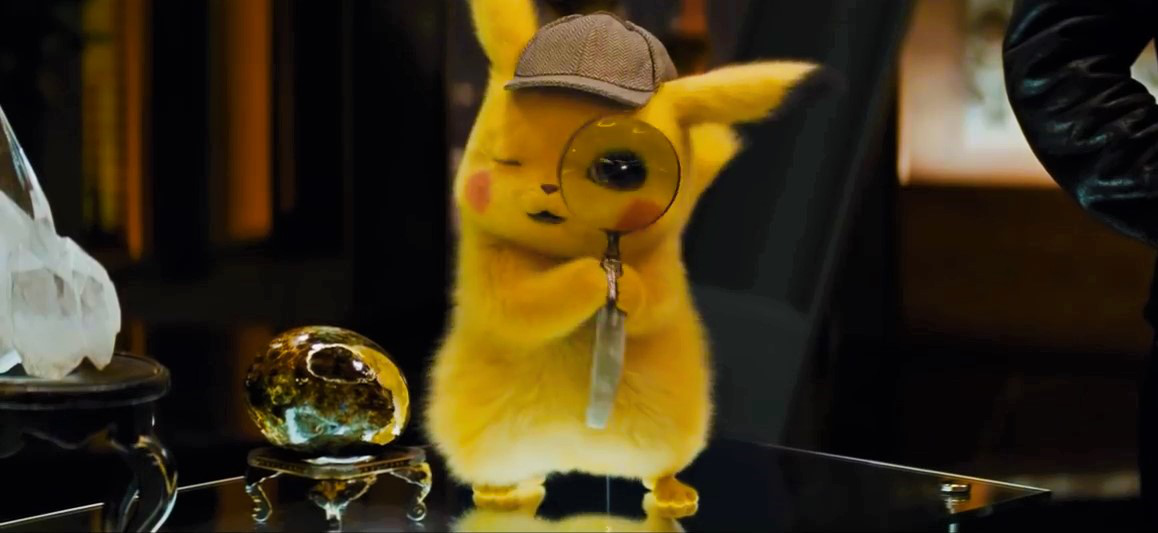

In [9]:
image

### Отрисовка изображени

Мы также можем использовать метод `show` объектов PIL для отображения изображения. Обратите внимание, что этот метод может работать или не работать в зависимости от ваших настроек.

In [11]:
image.show()

Вы также можете использовать метод imshow из библиотеки matplotlib для отображения изображения.

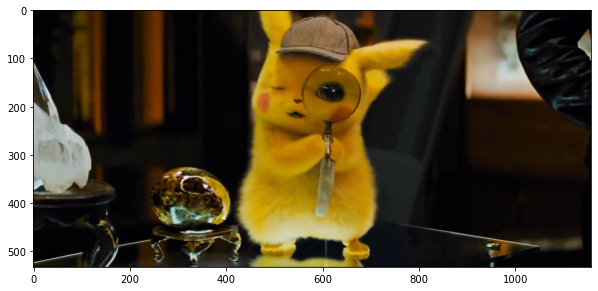

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(image)
plt.show()

Вы также можете загрузить изображение, используя его полный путь. Это пригодится, если изображение отсутствует в вашем рабочем каталоге.


In [14]:
image = Image.open(image_path)

<p>Вы можете использовать атрибуты объекта изображения для получения информации. Формат атрибута - это расширение или формат изображения.
<p>Атрибут size возвращает кортеж, первый элемент - это количество пикселей, составляющих ширину, а второй элемент - количество пикселей, составляющих высоту изображения.

In [15]:
print(image.size)

(1158, 533)


Ниже приведена строка, определяющая используемый формат пикселей. В данном случае это «RGB». RGB - это цветовое пространство, в котором красный, зеленый и синий складываются вместе для получения других цветов.

In [16]:
print(image.mode)

RGB


Метод Image.open не загружает данные изображения в память компьютера. Метод load объекта PIL считывает содержимое файла, декодирует его и расширяет изображение в память.

In [17]:
im = image.load()

Затем мы можем проверить интенсивность изображения в 𝑥 -м столбце и 𝑦 -й строке:

In [18]:
x = 0
y = 1
im[y,x]

(2, 2, 4)

Мы будем использовать форму массива для доступа к элементам.

Вы можете сохранить изображение в формате `jpg`, используя следующую команду:

In [20]:
image.save("Pika.jpg")

## Изображения в оттенках серого, квантование и цветовые каналы

### Изображения в оттенках серого

Модуль ImageOps содержит несколько готовых операций обработки изображений. Большинство операторов данного модуля работают только с изображениями в оттенках серого и/или RGB.

In [21]:
from PIL import ImageOps

Изображения в градациях серого имеют значения пикселей, представляющие количество света или интенсивность этого пикселя. Светлые оттенки серого имеют высокую интенсивность, тогда как более темные оттенки имеют более низкую интенсивность, то есть белый имеет самую высокую интенсивность, а черный - самую низкую.

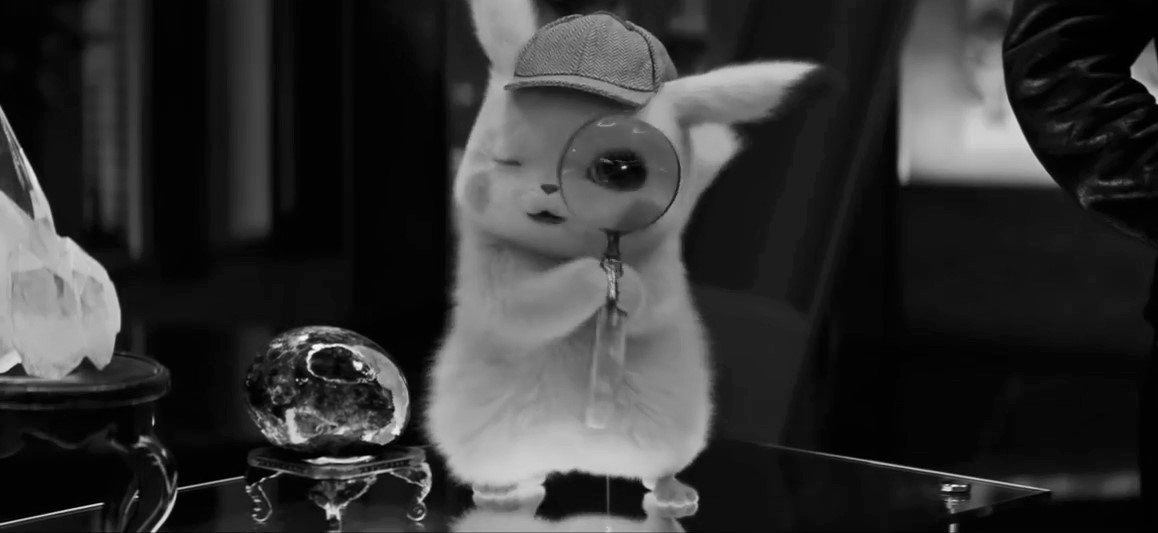

In [22]:
image_gray = ImageOps.grayscale(image) 
image_gray

Режим `L` для оттенков серого.

In [23]:
image_gray.mode

'L'

### Квантование

Квантование изображения - это количество уникальных значений интенсивности, которые может принимать любой заданный пиксель изображения. Для изображения в градациях серого это означает количество различных оттенков серого. Большинство изображений имеют 256 различных уровней. Можно уменьшить уровни, используя метод «quantize». Рассмотрим пример с сокращением количества уровней вдвое.

Половина уровней не дает заметной разницы.

In [24]:
image_gray.quantize(256 // 2)
image_gray.show()

Рассмотрим деление количества значений на два и сравним его с исходным изображением.

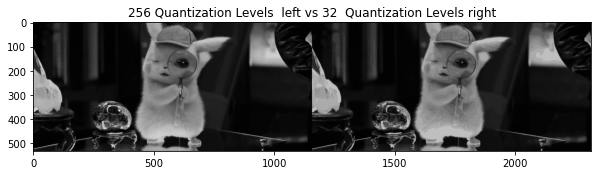

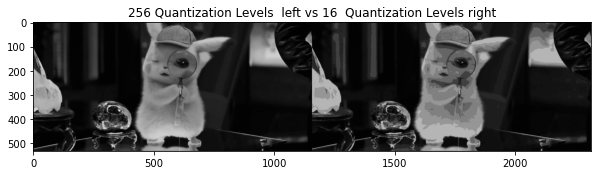

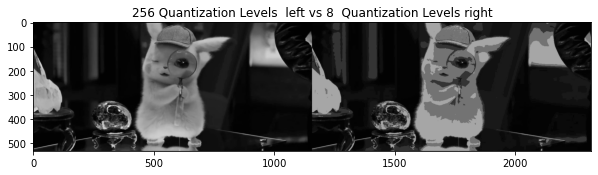

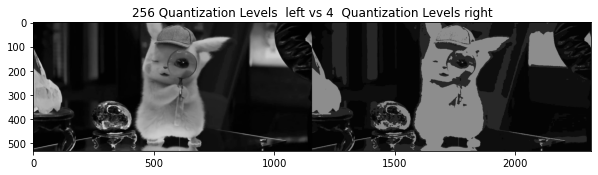

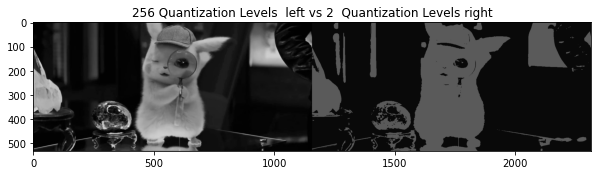

In [25]:
#get_concat_h(image_gray,  image_gray.quantize(256//2)).show(title="Pika") 
for n in range(3,8):
    plt.figure(figsize=(10,10))

    plt.imshow(get_concat_h(image_gray,  image_gray.quantize(256//2**n))) 
    plt.title("256 Quantization Levels  left vs {}  Quantization Levels right".format(256//2**n))
    plt.show()

### Цветовые каналы

Мы также можем работать с разными цветовыми каналами. Рассмотрим следующее изображение:

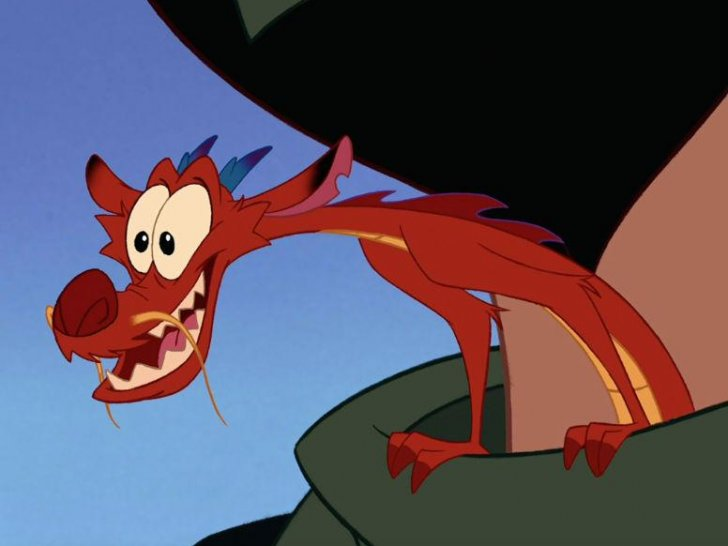

In [47]:
from IPython.display import Image
Image("Mushu.jpg")

In [48]:
mushu = "Mushu.jpg"

In [49]:
from PIL import Image

In [50]:
Mushu = Image.open(mushu)
type(Mushu)

PIL.JpegImagePlugin.JpegImageFile

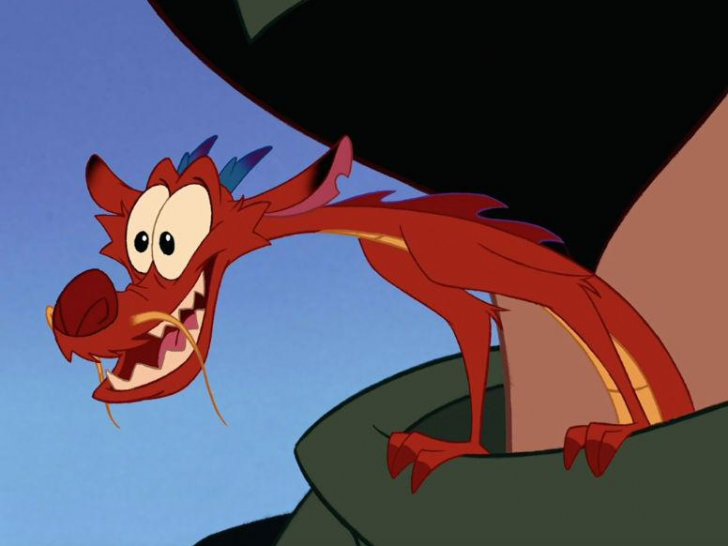

In [51]:
Mushu

Можно получить различные цветовые каналы RGB и назначить их переменным  red ,  green  и  blue :

In [52]:
red, green, blue = Mushu.split()

Помещая цветное изображение рядом с красным каналом в градациях серого, можно увидеть, что области с красным цветом имеют более высокие значения интенсивности.

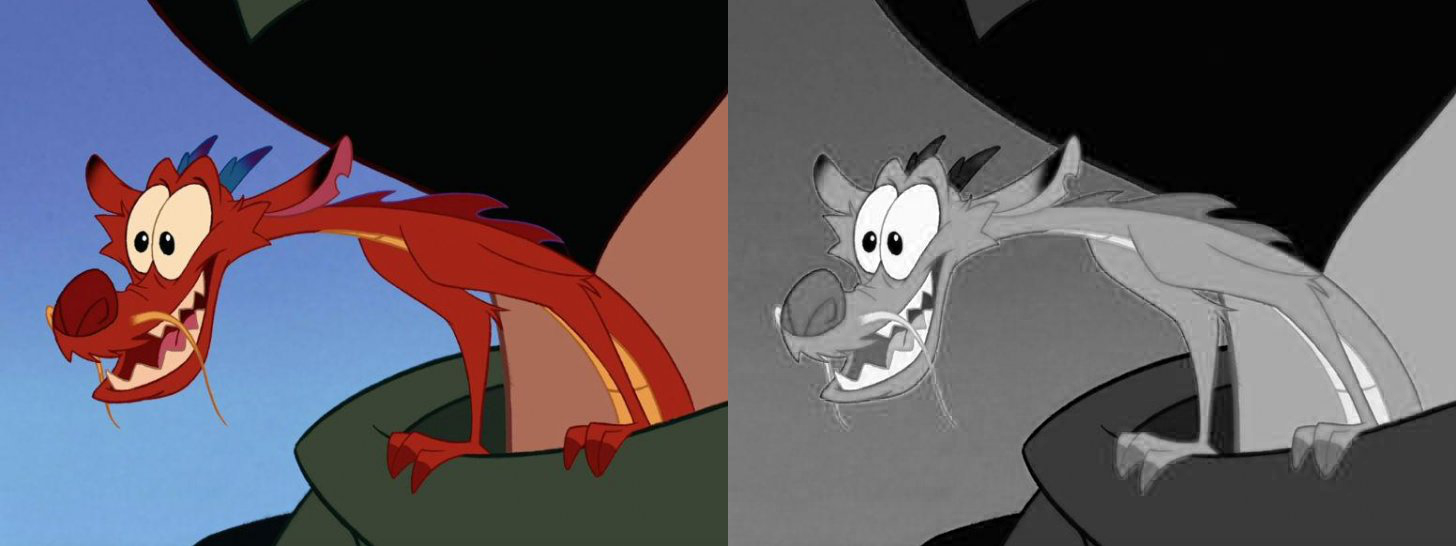

In [33]:
get_concat_h(Mushu, red)

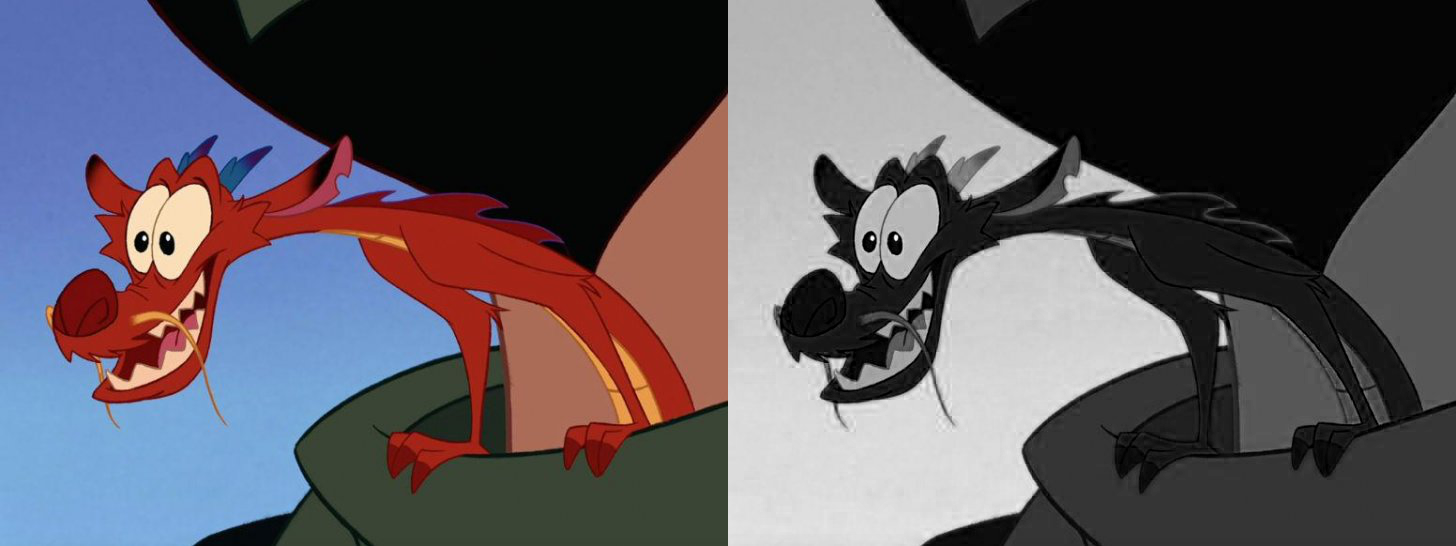

In [34]:
get_concat_h(Mushu, blue)

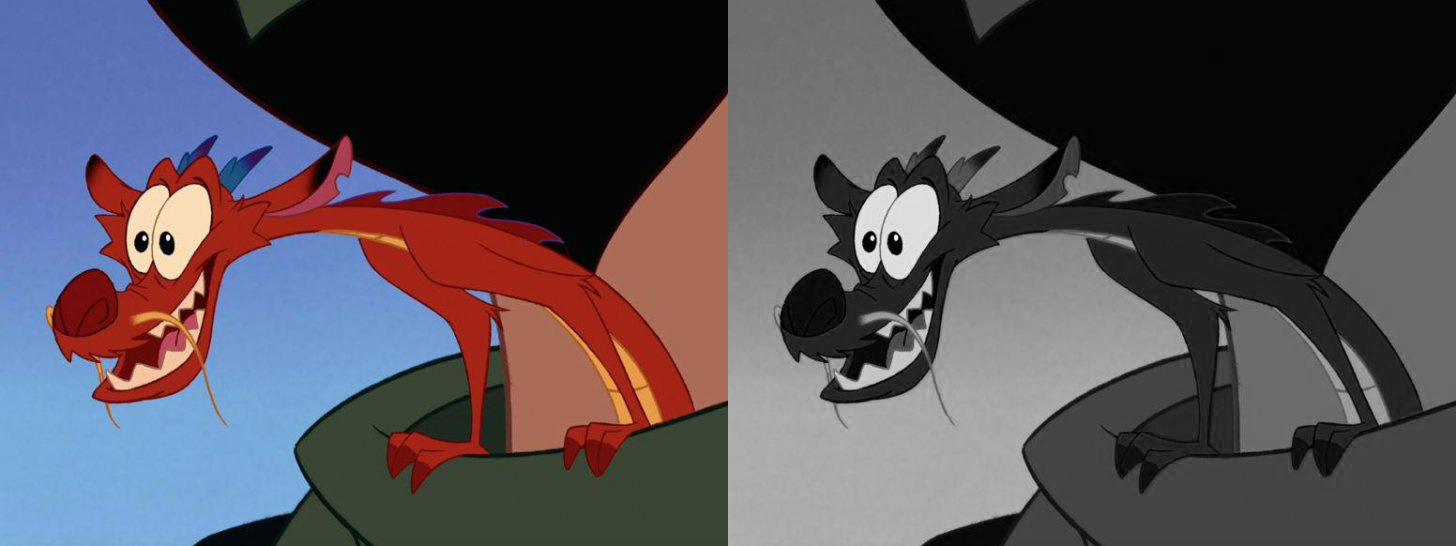

In [35]:
get_concat_h(Mushu, green)

## Изображения PIL в массивах NumPy

NumPy - это библиотека Python, позволяющая работать с многомерными массивами и матрицами. Можно преобразовать изображение PIL в массив NumPy. Используем asarray() или функцию массива из NumPy для преобразования изображений PIL в массивы NumPy. Для начала, импортируем модуль numpy:

In [36]:
import numpy as np

Применяем его к изображению PIL, получаем массив numpy:

In [53]:
array= np.asarray(Mushu)
print(type(array))

<class 'numpy.ndarray'>


np.asarray превращает исходное изображение в массив numpy. Очень часто необходимо не напрямую манипулировать изображением. В этом случае необходимо создать копию изображения для дальнейших манипуляций. Метод `np.array` создает новую копию изображения, так что исходная остается неизменной.

In [54]:
array = np.array(Mushu)

Атрибут <code> shape </code> объекта `numpy.array` возвращает кортеж, соответствующий его размерам, первый элемент дает количество строк или высоту изображения, второй элемент - это количество столбцы или ширина изображения. Последний элемент - количество цветовых каналов.

In [55]:
# summarize shape
print(array.shape)

(546, 728, 3)


или (строки, столбцы, цвета). Каждый элемент на оси цвета соответствует следующему формату значений (R, G, B).

Мы можем просмотреть значения интенсивности, распечатав массив, они варьируются от 0 до 255 или 28 (8-битные).

In [56]:
print(array)

[[[ 88 111 181]
  [ 88 111 181]
  [ 88 111 181]
  ...
  [  4   6   5]
  [  4   6   5]
  [  4   6   5]]

 [[ 88 111 181]
  [ 88 111 181]
  [ 88 111 181]
  ...
  [  4   6   5]
  [  4   6   5]
  [  4   6   5]]

 [[ 88 111 181]
  [ 88 111 181]
  [ 88 111 181]
  ...
  [  4   6   5]
  [  4   6   5]
  [  4   6   5]]

 ...

 [[124 175 222]
  [125 176 223]
  [126 177 224]
  ...
  [ 56  67  51]
  [ 56  67  51]
  [ 56  67  51]]

 [[125 176 221]
  [125 176 221]
  [126 177 222]
  ...
  [ 57  68  52]
  [ 57  68  52]
  [ 57  68  52]]

 [[125 176 221]
  [125 176 221]
  [126 177 222]
  ...
  [ 57  68  52]
  [ 57  68  52]
  [ 57  68  52]]]


Значения интенсивности - это 8-битные беззнаковые данные.

In [57]:
array[0, 0]

array([ 88, 111, 181], dtype=uint8)

Мы можем найти максимальное и минимальное значение интенсивности массива:

In [58]:
array.min()

0

In [59]:
array.max()

255

### Индексирование

Вы можете построить массив как изображение:

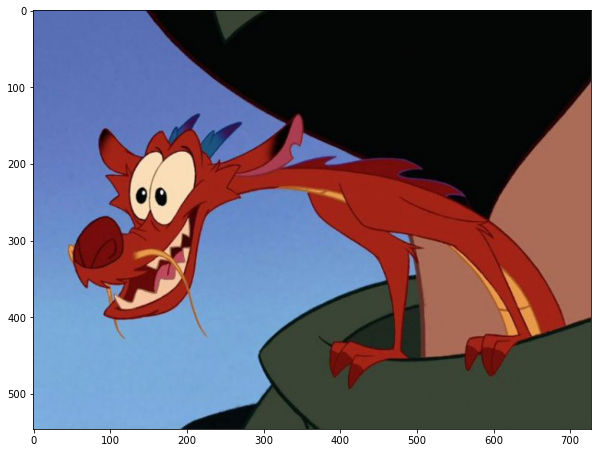

In [60]:
plt.figure(figsize=(10,10))
plt.imshow(array)
plt.show()

Вы можете использовать нарезку numpy, например, можно вернуть первые 256 строк, соответствующих верхней половине изображения:

In [61]:
rows = 256

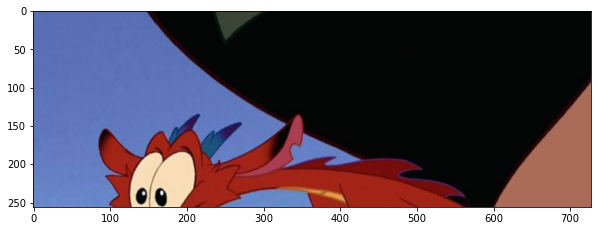

In [62]:
plt.figure(figsize=(10,10))
plt.imshow(array[0:rows,:,:])
plt.show()

Можно вернуть первые 256 столбцов, соответствующих первой половине изображения.

In [63]:
columns = 256

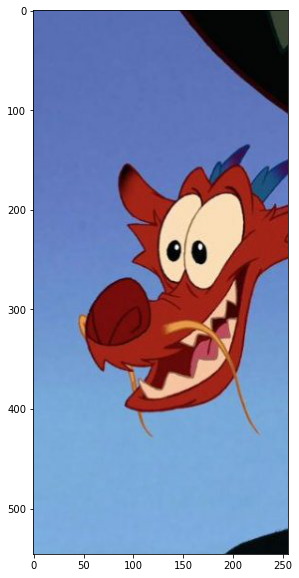

In [64]:
plt.figure(figsize=(10,10))
plt.imshow(array[:,0:columns,:])
plt.show()

Если вы хотите переназначить массив другой переменной, вы должны использовать метод `copy`.

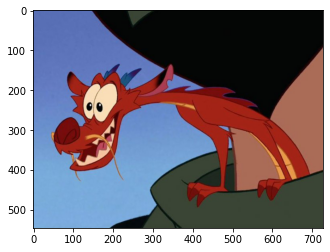

In [65]:
A = array.copy()
plt.imshow(A)
plt.show()

Если мы не применим метод copy (), переменная будет указывать на то же место в памяти. Рассмотрим массив B. Если мы установим все значения массива A равными нулю, поскольку B указывает на A, значения B тоже будут равны нулю:

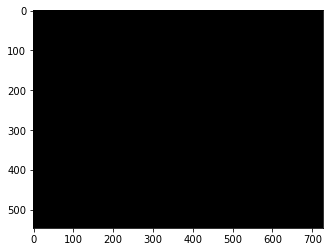

In [67]:
B = A
A[:,:,:] = 0
plt.imshow(B)
plt.show()

Также можно работать с разными цветовыми каналами. Рассмотрим изображение:

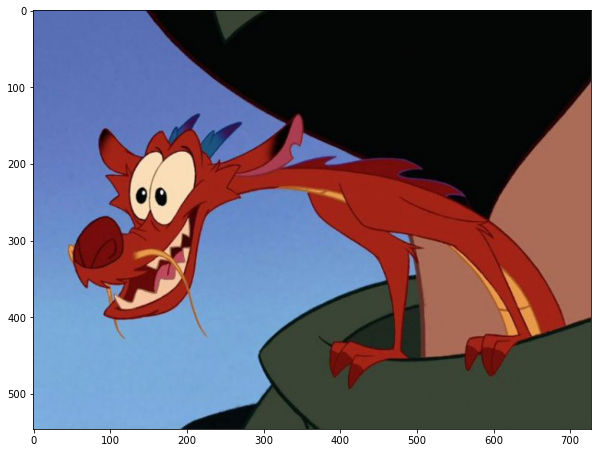

In [68]:
Mushu_array = np.array(Mushu)
plt.figure(figsize=(10,10))
plt.imshow(Mushu_array)
plt.show()

Можно построить красный канал как значения интенсивности красного канала.

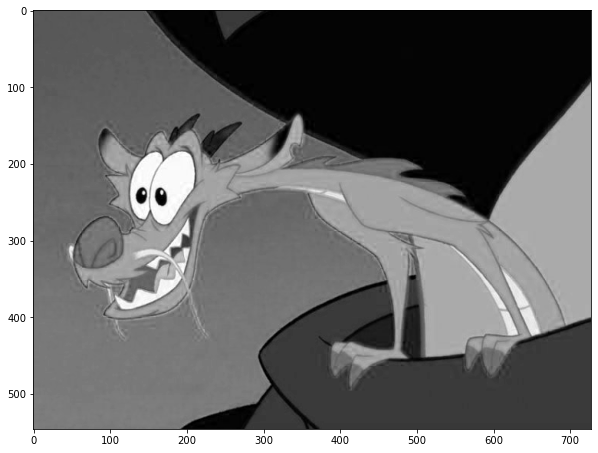

In [69]:
Mushu_array = np.array(Mushu)
plt.figure(figsize=(10,10))
plt.imshow(Mushu_array[:,:,0], cmap='gray')
plt.show()

Можно создать новый массив и обнулить все каналы, кроме красного.

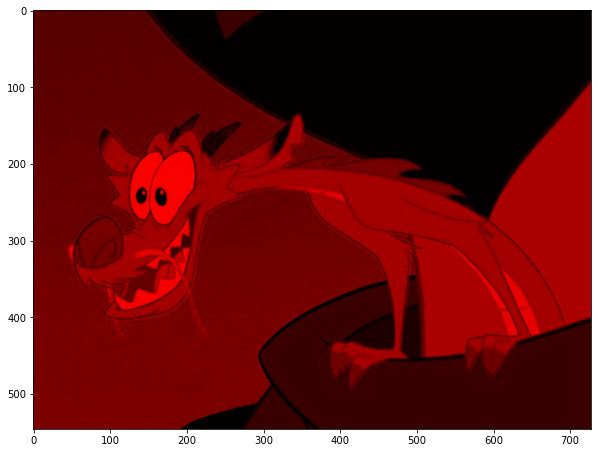

In [70]:
Mushu_red = Mushu_array.copy()
Mushu_red[:,:,1] = 0
Mushu_red[:,:,2] = 0
plt.figure(figsize=(10,10))
plt.imshow(Mushu_red)
plt.show()

То же самое можно сделать и с синим:

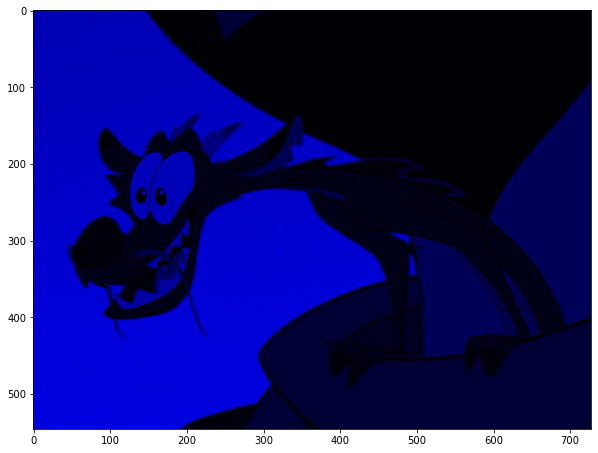

In [71]:
Mushu_blue = Mushu_array.copy()
Mushu_blue[:,:,0] = 0
Mushu_blue[:,:,1] = 0
plt.figure(figsize=(10,10))
plt.imshow(Mushu_blue)
plt.show()

Рассмотрим на примере преобразование изображения в numpy-массив, извлечем из него синий канал и построим изображение.

In [74]:
Mushu_blue[:,:,2] = 0

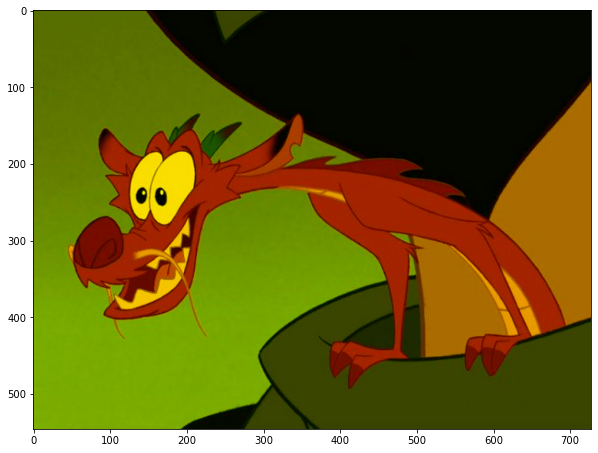

In [75]:
blue_Mushu = Image.open('Mushu.jpg')
blue_array = np.array(blue_Mushu)
blue_array[:,:,2] = 0
plt.figure(figsize=(10,10))
plt.imshow(blue_array)
plt.show()